# IoT Simulation — Smart Manufacturing

This notebook simulates **7 machines operating simultaneously** and continuously sending sensor readings to the existing Smart Twin.

The trained models are **not retrained here**.

Pipeline:

```text
IoT Simulation Data
        ↓
7 machine streams
        ↓
One cycle from every active machine
        ↓
Smart Twin
   ├── XGBoost → failure probability
   └── LightGBM → predicted RUL
        ↓
Risk / Health / Maintenance
```

The simulation dataset keeps the same core feature structure used by the trained Smart Twin, with `Timestamp` and `Simulation_Fault` added for simulation/analysis.


## Important distinction

`Simulation_Fault` is **not** an input to either ML model.

It exists only so we can understand which simulated degradation scenario produced a machine's sensor behavior.

The Smart Twin itself receives only the same model features used in the completed Smart Twin notebook.


In [1]:
# ============================================
# STEP 1: IMPORTS & SETUP
# ============================================

import os
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, clear_output

print("IoT simulation environment ready.")


Matplotlib is building the font cache; this may take a moment.


IoT simulation environment ready.


In [2]:
# ============================================
# STEP 2: LOAD TRAINED MODELS
# ============================================

failure_model_path = "../models/failure_prediction_model.pkl"
rul_model_path = "../models/rul_prediction_model.pkl"

failure_model = joblib.load(failure_model_path)
rul_model = joblib.load(rul_model_path)

print("Models loaded successfully!")
print("Failure model:", type(failure_model))
print("RUL model:", type(rul_model))


Models loaded successfully!
Failure model: <class 'sklearn.pipeline.Pipeline'>
RUL model: <class 'sklearn.pipeline.Pipeline'>


In [3]:
# ============================================
# STEP 3: MODEL FEATURE DEFINITIONS
# ============================================

# These are the same feature definitions used
# by the completed Smart Twin notebook.

failure_features = [
    "Cycle",
    "Temperature_C",
    "Vibration_mm_s",
    "Pressure_bar",
    "Rotational_Speed_RPM",
    "Load_Fraction",
    "Torque_Nm",
    "Current_A",
    "Acoustic_dB",
    "Wear_Level",
    "Machine_Type"
]

rul_features = [
    "Cycle",
    "Temperature_C",
    "Vibration_mm_s",
    "Pressure_bar",
    "Rotational_Speed_RPM",
    "Load_Fraction",
    "Torque_Nm",
    "Current_A",
    "Acoustic_dB",
    "Wear_Level",
    "Health_Index",
    "Anomaly_Score",
    "Machine_Type"
]

print("Failure model features:", len(failure_features))
print("RUL model features:", len(rul_features))


Failure model features: 11
RUL model features: 13


In [5]:
# ============================================
# STEP 4: LOAD IOT SIMULATION DATA
# ============================================

data_path = "../data/iot/iot_simulation_data.csv"

iot_df = pd.read_csv(data_path)

print("IoT simulation dataset loaded successfully!")
print("Shape:", iot_df.shape)

display(iot_df.head())


IoT simulation dataset loaded successfully!
Shape: (1930, 16)


,Timestamp,Machine_ID,Machine_Type,Cycle,Temperature_C,Vibration_mm_s,Pressure_bar,Rotational_Speed_RPM,Load_Fraction,Torque_Nm,Current_A,Acoustic_dB,Wear_Level,Health_Index,Anomaly_Score,Simulation_Fault
0,2026-08-01 08:00:00,CNC_001,CNC_Mill,1,69.030303,0.213912,2.113994,1517.415010,0.656548,46.756227,9.199260,55.818277,0.0000,100.000,0.1342,BEARING_WEAR
1,2026-08-01 08:01:00,CNC_001,CNC_Mill,2,69.089661,0.167449,2.139051,1517.500142,0.594057,46.788014,9.444278,55.515707,0.0000,99.961,0.2990,BEARING_WEAR
2,2026-08-01 08:02:00,CNC_001,CNC_Mill,3,69.030239,0.246411,2.120718,1522.832970,0.628487,46.321709,9.651838,54.939203,0.0022,99.760,0.2269,BEARING_WEAR
3,2026-08-01 08:03:00,CNC_001,CNC_Mill,4,69.040893,0.205632,2.114275,1534.355835,0.695731,48.495093,9.884200,54.581711,0.0000,99.884,0.0469,BEARING_WEAR
4,2026-08-01 08:04:00,CNC_001,CNC_Mill,5,68.651431,0.200355,2.085129,1515.119912,0.593584,48.107525,9.029107,54.332662,0.0006,99.802,0.2841,BEARING_WEAR


In [6]:
# ============================================
# STEP 5: VALIDATE IOT DATA
# ============================================

required_columns = sorted(
    set(failure_features + rul_features + [
        "Timestamp",
        "Machine_ID",
        "Machine_Type",
        "Cycle",
        "Simulation_Fault"
    ])
)

missing_columns = [
    column
    for column in required_columns
    if column not in iot_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("All required IoT columns are available.")
print("Missing values:", int(iot_df.isna().sum().sum()))
print("Number of machines:", iot_df["Machine_ID"].nunique())
print("Number of machine types:", iot_df["Machine_Type"].nunique())


All required IoT columns are available.
Missing values: 0
Number of machines: 7
Number of machine types: 7


In [7]:
# ============================================
# STEP 6: INSPECT THE 7 SIMULATED MACHINES
# ============================================

machine_summary = (
    iot_df.groupby(
        ["Machine_ID", "Machine_Type", "Simulation_Fault"]
    )
    .agg(
        Start_Cycle=("Cycle", "min"),
        End_Cycle=("Cycle", "max"),
        Readings=("Cycle", "count")
    )
    .reset_index()
)

display(machine_summary)

print("Machine IDs:")
print(iot_df["Machine_ID"].unique().tolist())


,Machine_ID,Machine_Type,Simulation_Fault,Start_Cycle,End_Cycle,Readings
0,CNC_001,CNC_Mill,BEARING_WEAR,1,260,260
1,COMP_003,Compressor,VIBRATION,1,290,290
2,MOTOR_004,Electric_Motor,ELECTRICAL,1,240,240
3,PRESS_006,Hydraulic_Press,PRESSURE,1,275,275
4,PUMP_002,Hydraulic_Pump,OVERHEATING,1,310,310
5,ROBOT_007,Industrial_Robot,ACTUATOR_DEGRADATION,1,225,225
6,TURB_005,Turbine,MISALIGNMENT,1,330,330


Machine IDs:
['CNC_001', 'PUMP_002', 'COMP_003', 'MOTOR_004', 'TURB_005', 'PRESS_006', 'ROBOT_007']


In [8]:
# ============================================
# STEP 7: CHECK SIMULATION FAULT DISTRIBUTION
# ============================================

print("Simulation fault distribution:")

display(
    iot_df["Simulation_Fault"]
    .value_counts()
    .rename_axis("Simulation_Fault")
    .reset_index(name="Readings")
)


Simulation fault distribution:


,Simulation_Fault,Readings
0,MISALIGNMENT,330
1,OVERHEATING,310
2,VIBRATION,290
3,PRESSURE,275
4,BEARING_WEAR,260
5,ELECTRICAL,240
6,ACTUATOR_DEGRADATION,225


In [9]:
# ============================================
# STEP 8: SMART TWIN MAINTENANCE LOGIC
# ============================================

def get_maintenance_recommendation(
    failure_risk,
    predicted_rul
):
    if failure_risk == "HIGH" or predicted_rul <= 20:
        return "IMMEDIATE MAINTENANCE"

    elif failure_risk == "MEDIUM" or predicted_rul <= 50:
        return "SCHEDULE INSPECTION"

    else:
        return "NORMAL OPERATION"


In [10]:
# ============================================
# STEP 9: SMART TWIN HEALTH SCORE
# ============================================

def calculate_health_score(
    failure_probability,
    predicted_rul
):
    failure_score = (
        1 - failure_probability
    ) * 100

    rul_score = min(
        predicted_rul,
        100
    )

    health_score = (
        0.6 * failure_score
        +
        0.4 * rul_score
    )

    return round(
        health_score,
        2
    )


In [11]:
# ============================================
# STEP 10: SMART TWIN PREDICTION FUNCTION
# ============================================

def predict_machine_state(machine_data):

    machine_df = pd.DataFrame([machine_data])

    # ----------------------------------------
    # FAILURE PREDICTION
    # ----------------------------------------

    failure_input = machine_df[
        failure_features
    ]

    failure_prediction = failure_model.predict(
        failure_input
    )[0]

    failure_probability = failure_model.predict_proba(
        failure_input
    )[0][1]

    # ----------------------------------------
    # RUL PREDICTION
    # ----------------------------------------

    rul_input = machine_df[
        rul_features
    ]

    predicted_rul = rul_model.predict(
        rul_input
    )[0]

    predicted_rul = max(
        0,
        float(predicted_rul)
    )

    # ----------------------------------------
    # FAILURE RISK
    # ----------------------------------------

    if failure_probability >= 0.70:
        failure_risk = "HIGH"

    elif failure_probability >= 0.30:
        failure_risk = "MEDIUM"

    else:
        failure_risk = "LOW"

    # ----------------------------------------
    # RUL STATUS
    # ----------------------------------------

    if predicted_rul <= 20:
        rul_status = "CRITICAL"

    elif predicted_rul <= 50:
        rul_status = "WARNING"

    else:
        rul_status = "HEALTHY"

    # ----------------------------------------
    # OVERALL MACHINE STATUS
    # ----------------------------------------

    if (
        failure_risk == "HIGH"
        or rul_status == "CRITICAL"
    ):
        overall_status = "CRITICAL"

    elif (
        failure_risk == "MEDIUM"
        or rul_status == "WARNING"
    ):
        overall_status = "WARNING"

    else:
        overall_status = "HEALTHY"

    # ----------------------------------------
    # MAINTENANCE
    # ----------------------------------------

    maintenance_action = get_maintenance_recommendation(
        failure_risk,
        predicted_rul
    )

    # ----------------------------------------
    # HEALTH SCORE
    # ----------------------------------------

    health_score = calculate_health_score(
        failure_probability,
        predicted_rul
    )

    return {
        "failure_prediction": int(
            failure_prediction
        ),
        "failure_probability": round(
            float(failure_probability),
            4
        ),
        "failure_risk": failure_risk,
        "predicted_rul_cycles": round(
            predicted_rul,
            2
        ),
        "rul_status": rul_status,
        "overall_status": overall_status,
        "maintenance_action": maintenance_action,
        "health_score": health_score
    }

print("Smart Twin prediction function ready.")


Smart Twin prediction function ready.


In [12]:
# ============================================
# STEP 11: TEST ONE SIMULATED MACHINE READING
# ============================================

sample_reading = iot_df.iloc[0].to_dict()

result = predict_machine_state(
    sample_reading
)

print("SINGLE IOT READING")
print("===================")

print("Machine:", sample_reading["Machine_ID"])
print("Type:", sample_reading["Machine_Type"])
print("Cycle:", sample_reading["Cycle"])
print("Simulation Fault:", sample_reading["Simulation_Fault"])

print("\nSMART TWIN RESULT")
print("=================")

for key, value in result.items():
    print(f"{key}: {value}")


SINGLE IOT READING
Machine: CNC_001
Type: CNC_Mill
Cycle: 1
Simulation Fault: BEARING_WEAR

SMART TWIN RESULT
failure_prediction: 0
failure_probability: 0.0001
failure_risk: LOW
predicted_rul_cycles: 256.45
rul_status: HEALTHY
overall_status: HEALTHY
maintenance_action: NORMAL OPERATION
health_score: 99.98999786376953


In [13]:
# ============================================
# STEP 12: PREPARE 7 PARALLEL MACHINE STREAMS
# ============================================

# Each machine gets its own ordered stream.
# We will advance all active machines one cycle
# at a time instead of processing one machine
# completely before moving to the next.

machine_streams = {}

for machine_id, machine_data in iot_df.groupby(
    "Machine_ID",
    sort=False
):
    machine_streams[machine_id] = (
        machine_data
        .sort_values("Cycle")
        .reset_index(drop=True)
    )

print("Machine streams created:")
for machine_id, stream in machine_streams.items():
    print(
        f"{machine_id}: "
        f"{len(stream)} readings"
    )

print(
    "\nTotal simulated machines:",
    len(machine_streams)
)


Machine streams created:
CNC_001: 260 readings
PUMP_002: 310 readings
COMP_003: 290 readings
MOTOR_004: 240 readings
TURB_005: 330 readings
PRESS_006: 275 readings
ROBOT_007: 225 readings

Total simulated machines: 7


In [14]:
# ============================================
# STEP 13: RUN ONE PARALLEL SIMULATION CYCLE
# ============================================

# A simulation cycle means:
# one new reading from EVERY active machine.

parallel_cycle_index = 0

parallel_readings = []

for machine_id, stream in machine_streams.items():

    if parallel_cycle_index < len(stream):

        row = stream.iloc[
            parallel_cycle_index
        ]

        parallel_readings.append(
            row.to_dict()
        )

parallel_cycle_df = pd.DataFrame(
    parallel_readings
)

print(
    "Machines producing readings:",
    len(parallel_cycle_df)
)

display(
    parallel_cycle_df[
        [
            "Machine_ID",
            "Machine_Type",
            "Cycle",
            "Temperature_C",
            "Vibration_mm_s",
            "Wear_Level",
            "Health_Index"
        ]
    ]
)


Machines producing readings: 7


,Machine_ID,Machine_Type,Cycle,Temperature_C,Vibration_mm_s,Wear_Level,Health_Index
0,CNC_001,CNC_Mill,1,69.030303,0.213912,0.0000,100.000
1,PUMP_002,Hydraulic_Pump,1,70.353479,0.213799,0.0000,100.000
2,COMP_003,Compressor,1,68.087376,0.197819,0.0064,99.518
3,MOTOR_004,Electric_Motor,1,71.927367,0.214139,0.0000,100.000
4,TURB_005,Turbine,1,65.344591,0.192897,0.0000,100.000
5,PRESS_006,Hydraulic_Press,1,67.273010,0.196157,0.0139,98.958
6,ROBOT_007,Industrial_Robot,1,67.282751,0.218239,0.0063,99.528


In [15]:
# ============================================
# STEP 14: SMART TWIN ON ALL 7 MACHINES
# ============================================

parallel_results = []

for _, row in parallel_cycle_df.iterrows():

    result = predict_machine_state(
        row.to_dict()
    )

    result["Machine_ID"] = row["Machine_ID"]
    result["Machine_Type"] = row["Machine_Type"]
    result["Cycle"] = row["Cycle"]
    result["Timestamp"] = row["Timestamp"]
    result["Simulation_Fault"] = row[
        "Simulation_Fault"
    ]

    parallel_results.append(result)

parallel_results_df = pd.DataFrame(
    parallel_results
)

display(
    parallel_results_df[
        [
            "Machine_ID",
            "Machine_Type",
            "Cycle",
            "failure_probability",
            "failure_risk",
            "predicted_rul_cycles",
            "rul_status",
            "overall_status",
            "maintenance_action",
            "health_score"
        ]
    ]
)


,Machine_ID,Machine_Type,Cycle,failure_probability,failure_risk,predicted_rul_cycles,rul_status,overall_status,maintenance_action,health_score
0,CNC_001,CNC_Mill,1,0.0001,LOW,256.45,HEALTHY,HEALTHY,NORMAL OPERATION,99.989998
1,PUMP_002,Hydraulic_Pump,1,0.0001,LOW,306.94,HEALTHY,HEALTHY,NORMAL OPERATION,99.989998
2,COMP_003,Compressor,1,0.0001,LOW,284.57,HEALTHY,HEALTHY,NORMAL OPERATION,99.989998
3,MOTOR_004,Electric_Motor,1,0.0001,LOW,238.10,HEALTHY,HEALTHY,NORMAL OPERATION,99.989998
4,TURB_005,Turbine,1,0.0001,LOW,327.21,HEALTHY,HEALTHY,NORMAL OPERATION,99.989998
5,PRESS_006,Hydraulic_Press,1,0.0001,LOW,273.77,HEALTHY,HEALTHY,NORMAL OPERATION,99.989998
6,ROBOT_007,Industrial_Robot,1,0.0001,LOW,224.29,HEALTHY,HEALTHY,NORMAL OPERATION,99.989998


In [16]:
# ============================================
# STEP 15: FULL 7-MACHINE SIMULATION
# ============================================

# Run the machines simultaneously in simulation time.
# At each simulation step, every machine contributes
# its next available sensor reading.

simulation_results = []

max_steps = max(
    len(stream)
    for stream in machine_streams.values()
)

print(
    "Starting simulation for",
    len(machine_streams),
    "machines..."
)

for step in range(max_steps):

    for machine_id, stream in machine_streams.items():

        if step >= len(stream):
            continue

        row = stream.iloc[step]
        machine_data = row.to_dict()

        result = predict_machine_state(
            machine_data
        )

        result["Timestamp"] = row["Timestamp"]
        result["Machine_ID"] = row["Machine_ID"]
        result["Machine_Type"] = row["Machine_Type"]
        result["Cycle"] = row["Cycle"]
        result["Simulation_Fault"] = row[
            "Simulation_Fault"
        ]

        simulation_results.append(
            result
        )

simulation_results_df = pd.DataFrame(
    simulation_results
)

print("Simulation completed.")
print(
    "Result shape:",
    simulation_results_df.shape
)

display(
    simulation_results_df.head(10)
)


Starting simulation for 7 machines...
Simulation completed.
Result shape: (1930, 13)


,failure_prediction,failure_probability,failure_risk,predicted_rul_cycles,rul_status,overall_status,maintenance_action,health_score,Timestamp,Machine_ID,Machine_Type,Cycle,Simulation_Fault
0,0,0.0001,LOW,256.45,HEALTHY,HEALTHY,NORMAL OPERATION,99.989998,2026-08-01 08:00:00,CNC_001,CNC_Mill,1,BEARING_WEAR
1,0,0.0001,LOW,306.94,HEALTHY,HEALTHY,NORMAL OPERATION,99.989998,2026-08-01 08:00:00,PUMP_002,Hydraulic_Pump,1,OVERHEATING
2,0,0.0001,LOW,284.57,HEALTHY,HEALTHY,NORMAL OPERATION,99.989998,2026-08-01 08:00:00,COMP_003,Compressor,1,VIBRATION
3,0,0.0001,LOW,238.10,HEALTHY,HEALTHY,NORMAL OPERATION,99.989998,2026-08-01 08:00:00,MOTOR_004,Electric_Motor,1,ELECTRICAL
4,0,0.0001,LOW,327.21,HEALTHY,HEALTHY,NORMAL OPERATION,99.989998,2026-08-01 08:00:00,TURB_005,Turbine,1,MISALIGNMENT
5,0,0.0001,LOW,273.77,HEALTHY,HEALTHY,NORMAL OPERATION,99.989998,2026-08-01 08:00:00,PRESS_006,Hydraulic_Press,1,PRESSURE
6,0,0.0001,LOW,224.29,HEALTHY,HEALTHY,NORMAL OPERATION,99.989998,2026-08-01 08:00:00,ROBOT_007,Industrial_Robot,1,ACTUATOR_DEGRADATION
7,0,0.0001,LOW,262.11,HEALTHY,HEALTHY,NORMAL OPERATION,99.989998,2026-08-01 08:01:00,CNC_001,CNC_Mill,2,BEARING_WEAR
8,0,0.0001,LOW,300.68,HEALTHY,HEALTHY,NORMAL OPERATION,99.989998,2026-08-01 08:01:00,PUMP_002,Hydraulic_Pump,2,OVERHEATING
9,0,0.0001,LOW,285.62,HEALTHY,HEALTHY,NORMAL OPERATION,99.989998,2026-08-01 08:01:00,COMP_003,Compressor,2,VIBRATION


In [17]:
# ============================================
# STEP 16: COMBINE SENSOR DATA + SMART TWIN
# ============================================

sensor_columns = [
    "Timestamp",
    "Machine_ID",
    "Machine_Type",
    "Cycle",
    "Temperature_C",
    "Vibration_mm_s",
    "Pressure_bar",
    "Rotational_Speed_RPM",
    "Load_Fraction",
    "Torque_Nm",
    "Current_A",
    "Acoustic_dB",
    "Wear_Level",
    "Health_Index",
    "Anomaly_Score",
    "Simulation_Fault"
]

sensor_data = iot_df[
    sensor_columns
].copy()

# Use a stable key because each machine has a cycle number.
smart_twin_stream_output = sensor_data.merge(
    simulation_results_df,
    on=[
        "Timestamp",
        "Machine_ID",
        "Machine_Type",
        "Cycle",
        "Simulation_Fault"
    ],
    how="inner"
)

print(
    "Complete IoT + Smart Twin output shape:",
    smart_twin_stream_output.shape
)

display(
    smart_twin_stream_output.head(10)
)


Complete IoT + Smart Twin output shape: (1930, 24)


,Timestamp,Machine_ID,Machine_Type,Cycle,Temperature_C,Vibration_mm_s,Pressure_bar,Rotational_Speed_RPM,Load_Fraction,Torque_Nm,...,Anomaly_Score,Simulation_Fault,failure_prediction,failure_probability,failure_risk,predicted_rul_cycles,rul_status,overall_status,maintenance_action,health_score
0,2026-08-01 08:00:00,CNC_001,CNC_Mill,1,69.030303,0.213912,2.113994,1517.415010,0.656548,46.756227,...,0.1342,BEARING_WEAR,0,0.0001,LOW,256.45,HEALTHY,HEALTHY,NORMAL OPERATION,99.989998
1,2026-08-01 08:01:00,CNC_001,CNC_Mill,2,69.089661,0.167449,2.139051,1517.500142,0.594057,46.788014,...,0.2990,BEARING_WEAR,0,0.0001,LOW,262.11,HEALTHY,HEALTHY,NORMAL OPERATION,99.989998
2,2026-08-01 08:02:00,CNC_001,CNC_Mill,3,69.030239,0.246411,2.120718,1522.832970,0.628487,46.321709,...,0.2269,BEARING_WEAR,0,0.0001,LOW,256.96,HEALTHY,HEALTHY,NORMAL OPERATION,99.989998
3,2026-08-01 08:03:00,CNC_001,CNC_Mill,4,69.040893,0.205632,2.114275,1534.355835,0.695731,48.495093,...,0.0469,BEARING_WEAR,0,0.0001,LOW,256.90,HEALTHY,HEALTHY,NORMAL OPERATION,99.989998
4,2026-08-01 08:04:00,CNC_001,CNC_Mill,5,68.651431,0.200355,2.085129,1515.119912,0.593584,48.107525,...,0.2841,BEARING_WEAR,0,0.0001,LOW,262.69,HEALTHY,HEALTHY,NORMAL OPERATION,99.989998
5,2026-08-01 08:05:00,CNC_001,CNC_Mill,6,68.610849,0.216351,2.101183,1530.176055,0.647134,45.986473,...,0.1565,BEARING_WEAR,0,0.0001,LOW,253.78,HEALTHY,HEALTHY,NORMAL OPERATION,99.989998
6,2026-08-01 08:06:00,CNC_001,CNC_Mill,7,68.304690,0.186773,2.092543,1513.226426,0.626944,47.778389,...,0.3396,BEARING_WEAR,0,0.0001,LOW,253.29,HEALTHY,HEALTHY,NORMAL OPERATION,99.989998
7,2026-08-01 08:07:00,CNC_001,CNC_Mill,8,69.033821,0.189346,2.090724,1521.180293,0.687660,47.869680,...,0.2179,BEARING_WEAR,0,0.0001,LOW,255.17,HEALTHY,HEALTHY,NORMAL OPERATION,99.989998
8,2026-08-01 08:08:00,CNC_001,CNC_Mill,9,68.620336,0.194883,2.136292,1529.145983,0.636815,48.007995,...,0.2230,BEARING_WEAR,0,0.0001,LOW,251.45,HEALTHY,HEALTHY,NORMAL OPERATION,99.989998
9,2026-08-01 08:09:00,CNC_001,CNC_Mill,10,70.719612,0.234976,2.147221,1551.339407,0.670143,47.922526,...,0.3307,BEARING_WEAR,0,0.0001,LOW,250.34,HEALTHY,HEALTHY,NORMAL OPERATION,99.989998


In [18]:
# ============================================
# STEP 17: MAINTENANCE ALERTS
# ============================================

maintenance_alerts = smart_twin_stream_output[
    smart_twin_stream_output[
        "maintenance_action"
    ] != "NORMAL OPERATION"
].copy()

maintenance_alerts = maintenance_alerts.sort_values(
    by=[
        "failure_probability",
        "predicted_rul_cycles"
    ],
    ascending=[
        False,
        True
    ]
)

print(
    "Total maintenance-triggering readings:",
    len(maintenance_alerts)
)

display(
    maintenance_alerts[
        [
            "Timestamp",
            "Machine_ID",
            "Machine_Type",
            "Cycle",
            "Simulation_Fault",
            "failure_probability",
            "failure_risk",
            "predicted_rul_cycles",
            "overall_status",
            "maintenance_action",
            "health_score"
        ]
    ].head(20)
)


Total maintenance-triggering readings: 481


,Timestamp,Machine_ID,Machine_Type,Cycle,Simulation_Fault,failure_probability,failure_risk,predicted_rul_cycles,overall_status,maintenance_action,health_score
1406,2026-08-01 13:06:00,TURB_005,Turbine,307,MISALIGNMENT,0.9983,HIGH,2.88,CRITICAL,IMMEDIATE MAINTENANCE,1.26
1704,2026-08-01 12:34:00,PRESS_006,Hydraulic_Press,275,PRESSURE,0.9981,HIGH,1.63,CRITICAL,IMMEDIATE MAINTENANCE,0.77
1695,2026-08-01 12:25:00,PRESS_006,Hydraulic_Press,266,PRESSURE,0.9981,HIGH,2.30,CRITICAL,IMMEDIATE MAINTENANCE,1.04
838,2026-08-01 12:28:00,COMP_003,Compressor,269,VIBRATION,0.9980,HIGH,2.29,CRITICAL,IMMEDIATE MAINTENANCE,1.04
568,2026-08-01 13:08:00,PUMP_002,Hydraulic_Pump,309,OVERHEATING,0.9980,HIGH,2.53,CRITICAL,IMMEDIATE MAINTENANCE,1.13
1094,2026-08-01 11:54:00,MOTOR_004,Electric_Motor,235,ELECTRICAL,0.9979,HIGH,2.71,CRITICAL,IMMEDIATE MAINTENANCE,1.21
1694,2026-08-01 12:24:00,PRESS_006,Hydraulic_Press,265,PRESSURE,0.9979,HIGH,3.03,CRITICAL,IMMEDIATE MAINTENANCE,1.34
1401,2026-08-01 13:01:00,TURB_005,Turbine,302,MISALIGNMENT,0.9979,HIGH,3.37,CRITICAL,IMMEDIATE MAINTENANCE,1.47
1702,2026-08-01 12:32:00,PRESS_006,Hydraulic_Press,273,PRESSURE,0.9979,HIGH,3.41,CRITICAL,IMMEDIATE MAINTENANCE,1.49
1426,2026-08-01 13:26:00,TURB_005,Turbine,327,MISALIGNMENT,0.9978,HIGH,1.82,CRITICAL,IMMEDIATE MAINTENANCE,0.86


In [19]:
# ============================================
# STEP 18: FINAL HEALTH DISTRIBUTIONS
# ============================================

print("Overall Machine Status:")
display(
    smart_twin_stream_output[
        "overall_status"
    ].value_counts()
)

print("\nFailure Risk:")
display(
    smart_twin_stream_output[
        "failure_risk"
    ].value_counts()
)

print("\nRUL Status:")
display(
    smart_twin_stream_output[
        "rul_status"
    ].value_counts()
)

print("\nMaintenance Action:")
display(
    smart_twin_stream_output[
        "maintenance_action"
    ].value_counts()
)


Overall Machine Status:


overall_status
HEALTHY     1449
CRITICAL     286
WARNING      195
Name: count, dtype: int64


Failure Risk:


failure_risk
LOW       1668
HIGH       254
MEDIUM       8
Name: count, dtype: int64


RUL Status:


rul_status
HEALTHY     1449
CRITICAL     286
WARNING      195
Name: count, dtype: int64


Maintenance Action:


maintenance_action
NORMAL OPERATION         1449
IMMEDIATE MAINTENANCE     286
SCHEDULE INSPECTION       195
Name: count, dtype: int64

In [20]:
# ============================================
# STEP 19: MACHINE-WISE FINAL STATE
# ============================================

# The last available reading represents the latest
# simulated state for each machine.

latest_machine_state = (
    smart_twin_stream_output
    .sort_values("Cycle")
    .groupby("Machine_ID", as_index=False)
    .tail(1)
    .sort_values(
        by="health_score"
    )
)

display(
    latest_machine_state[
        [
            "Machine_ID",
            "Machine_Type",
            "Cycle",
            "Simulation_Fault",
            "failure_probability",
            "failure_risk",
            "predicted_rul_cycles",
            "rul_status",
            "overall_status",
            "maintenance_action",
            "health_score"
        ]
    ]
)


,Machine_ID,Machine_Type,Cycle,Simulation_Fault,failure_probability,failure_risk,predicted_rul_cycles,rul_status,overall_status,maintenance_action,health_score
1099,MOTOR_004,Electric_Motor,240,ELECTRICAL,0.9968,HIGH,1.33,CRITICAL,CRITICAL,IMMEDIATE MAINTENANCE,0.73
1704,PRESS_006,Hydraulic_Press,275,PRESSURE,0.9981,HIGH,1.63,CRITICAL,CRITICAL,IMMEDIATE MAINTENANCE,0.77
1429,TURB_005,Turbine,330,MISALIGNMENT,0.9967,HIGH,1.64,CRITICAL,CRITICAL,IMMEDIATE MAINTENANCE,0.86
569,PUMP_002,Hydraulic_Pump,310,OVERHEATING,0.9977,HIGH,2.12,CRITICAL,CRITICAL,IMMEDIATE MAINTENANCE,0.98
1929,ROBOT_007,Industrial_Robot,225,ACTUATOR_DEGRADATION,0.9941,HIGH,1.86,CRITICAL,CRITICAL,IMMEDIATE MAINTENANCE,1.10
259,CNC_001,CNC_Mill,260,BEARING_WEAR,0.9939,HIGH,2.06,CRITICAL,CRITICAL,IMMEDIATE MAINTENANCE,1.19
859,COMP_003,Compressor,290,VIBRATION,0.9887,HIGH,3.89,CRITICAL,CRITICAL,IMMEDIATE MAINTENANCE,2.23


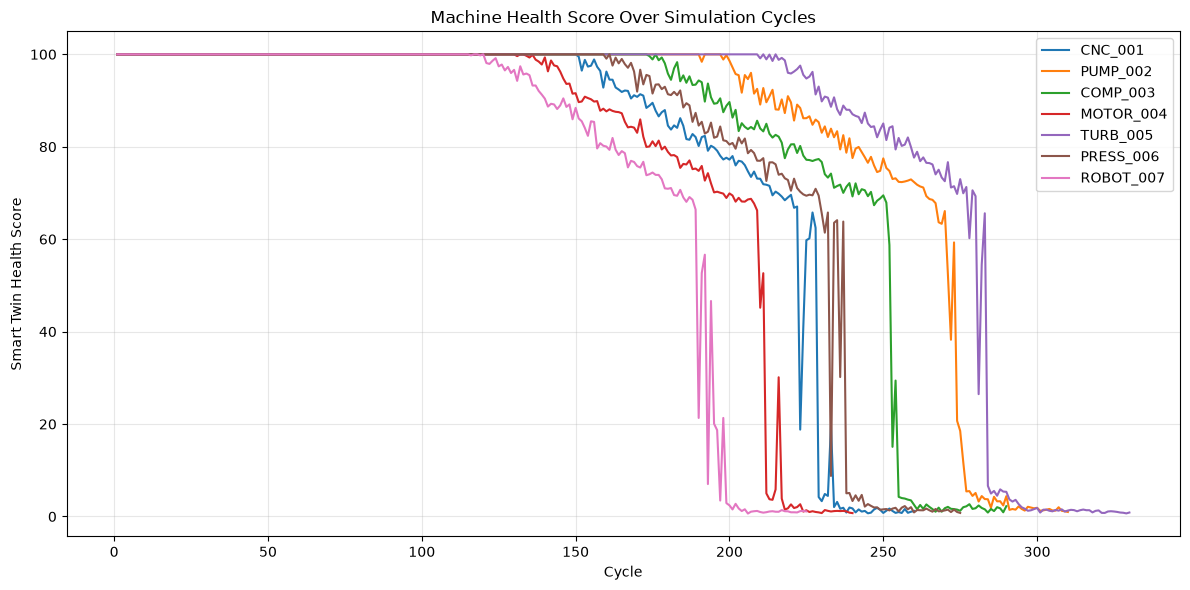

In [21]:
# ============================================
# STEP 20: HEALTH SCORE TRAJECTORY
# ============================================

plt.figure(figsize=(12, 6))

for machine_id in (
    smart_twin_stream_output["Machine_ID"]
    .unique()
):

    machine_data = (
        smart_twin_stream_output[
            smart_twin_stream_output[
                "Machine_ID"
            ] == machine_id
        ]
        .sort_values("Cycle")
    )

    plt.plot(
        machine_data["Cycle"],
        machine_data["health_score"],
        label=machine_id
    )

plt.xlabel("Cycle")
plt.ylabel("Smart Twin Health Score")
plt.title("Machine Health Score Over Simulation Cycles")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


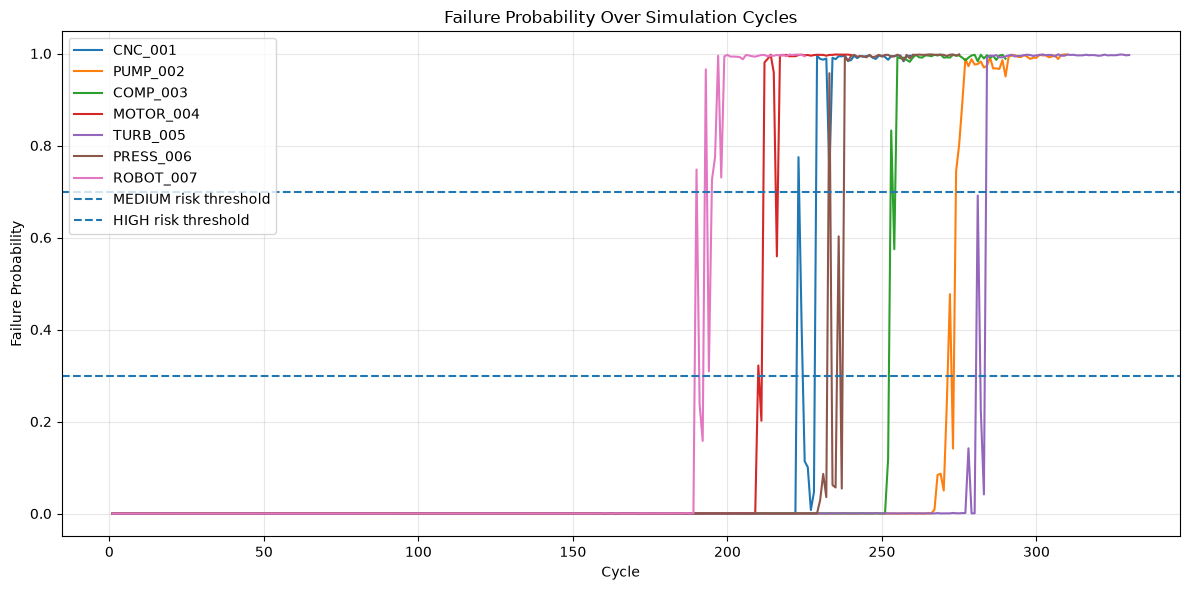

In [22]:
# ============================================
# STEP 21: FAILURE PROBABILITY TRAJECTORY
# ============================================

plt.figure(figsize=(12, 6))

for machine_id in (
    smart_twin_stream_output["Machine_ID"]
    .unique()
):

    machine_data = (
        smart_twin_stream_output[
            smart_twin_stream_output[
                "Machine_ID"
            ] == machine_id
        ]
        .sort_values("Cycle")
    )

    plt.plot(
        machine_data["Cycle"],
        machine_data["failure_probability"],
        label=machine_id
    )

plt.axhline(
    0.30,
    linestyle="--",
    label="MEDIUM risk threshold"
)

plt.axhline(
    0.70,
    linestyle="--",
    label="HIGH risk threshold"
)

plt.xlabel("Cycle")
plt.ylabel("Failure Probability")
plt.title("Failure Probability Over Simulation Cycles")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


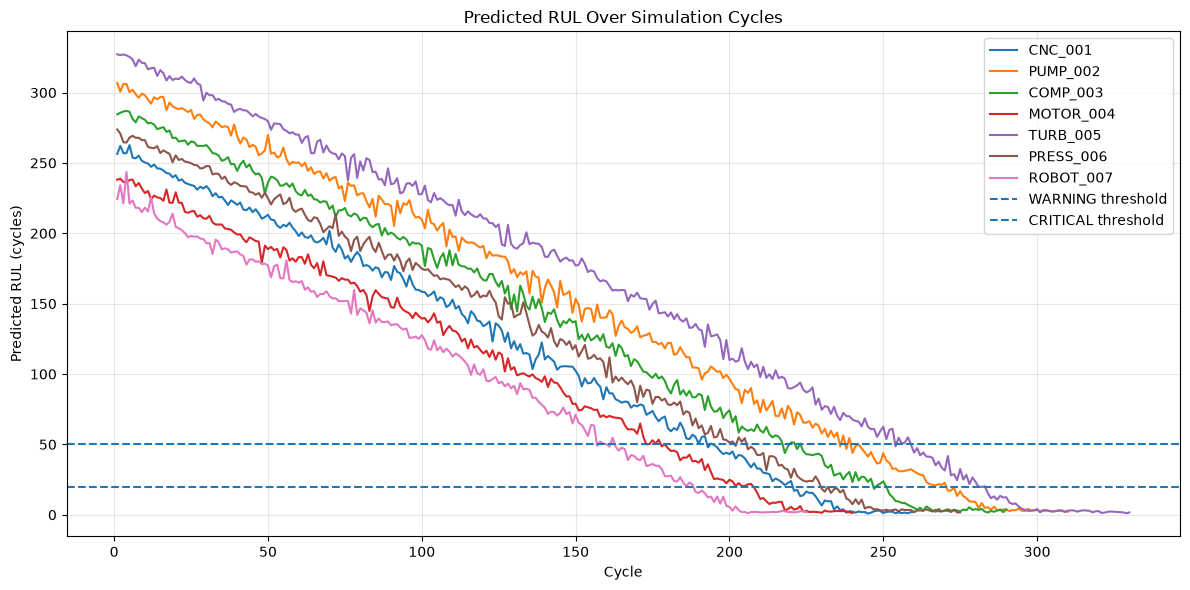

In [23]:
# ============================================
# STEP 22: RUL TRAJECTORY
# ============================================

plt.figure(figsize=(12, 6))

for machine_id in (
    smart_twin_stream_output["Machine_ID"]
    .unique()
):

    machine_data = (
        smart_twin_stream_output[
            smart_twin_stream_output[
                "Machine_ID"
            ] == machine_id
        ]
        .sort_values("Cycle")
    )

    plt.plot(
        machine_data["Cycle"],
        machine_data["predicted_rul_cycles"],
        label=machine_id
    )

plt.axhline(
    50,
    linestyle="--",
    label="WARNING threshold"
)

plt.axhline(
    20,
    linestyle="--",
    label="CRITICAL threshold"
)

plt.xlabel("Cycle")
plt.ylabel("Predicted RUL (cycles)")
plt.title("Predicted RUL Over Simulation Cycles")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [24]:
# ============================================
# STEP 23: SAVE SIMULATION OUTPUT
# ============================================

output_path = "../data/processed/iot_smart_twin_results.csv"

smart_twin_stream_output.to_csv(
    output_path,
    index=False
)

print("IoT + Smart Twin results saved successfully!")
print("Path:", output_path)
print(
    "Rows:",
    len(smart_twin_stream_output)
)


IoT + Smart Twin results saved successfully!
Path: ../data/processed/iot_smart_twin_results.csv
Rows: 1930


## Next stage

This notebook establishes the **simulated IoT layer**:

```text
7 machines
   ↓
time-ordered sensor readings
   ↓
simultaneous simulation steps
   ↓
Smart Twin
   ↓
failure + RUL + health + maintenance
```

The next phase will make this more realistic as a streaming system and then introduce the **AI Agent layer**.

The important boundary is preserved:

- IoT simulation produces sensor observations.
- XGBoost predicts failure.
- LightGBM predicts RUL.
- Smart Twin combines those predictions.
- The future Agent will reason over the resulting machine state.
